# 3.3. Errors and Exceptions Handling

Module M-227-04: Programming for Data Analytics

Instructor: Nadežda Zeņina

Course author: Dmitry Pavlyuk

## Previous lesson review

Warm-up: *https://ej.uz/rgiy*

* `with open(name, mode, encoding='utf-8') as file:` - `'r'`, `'w'`, `'a'`
* text: `file.read()`, `for line in file`; **CSV**: `csv.DictReader`, everything is a string
* **JSON**: `json.load()` / `json.dump()` → dictionaries and lists; **XML**: a tree; **Pickle**: any Python object

## Today

1. **Errors** - the three kinds of problems in a program
2. **Exception types** - how to read an error message
3. **Handling exceptions** - `try` / `except` / `else` / `finally`
4. **Exceptions in data work** - bad values, missing files, missing keys
5. **Raising your own exceptions** - `raise`

## Errors

Unfortunately, programs are full of errors.

* A program that works for some input data can produce an error for other data
* A program that works in one environment can produce an error in another

In data analytics this happens **all the time**: the file is missing, a column contains `"n/a"` instead of a number, one record has no `population` key. Catching these errors is an integral part of programming - the analysis must survive the imperfect data.

Syntax errors are found before the program runs, logic errors are found by tests (`assert`, lesson 3.1), and exceptions are the subject of today
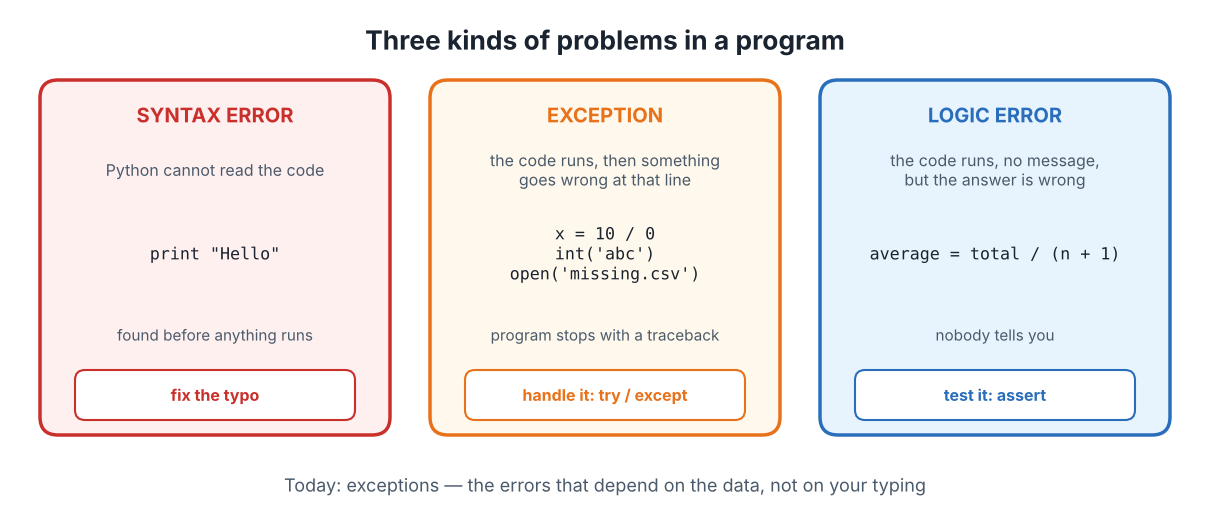

An **exception** is an event which occurs during the execution of a program and disrupts the normal flow of the program's instructions. If nobody handles it, the program **stops** at that line.

## Exception types

Exceptions are Python objects. They have different **types** and contain information about the error. Some standard exception types:

* `SyntaxError`, `NameError`, `TypeError`, `ValueError`
* `IndexError`, `KeyError`
* `ZeroDivisionError`, `FileNotFoundError`, `ModuleNotFoundError`

and many others: https://docs.python.org/3/library/exceptions.html

The last line of a traceback names the exception type and explains the problem; the arrow shows the line
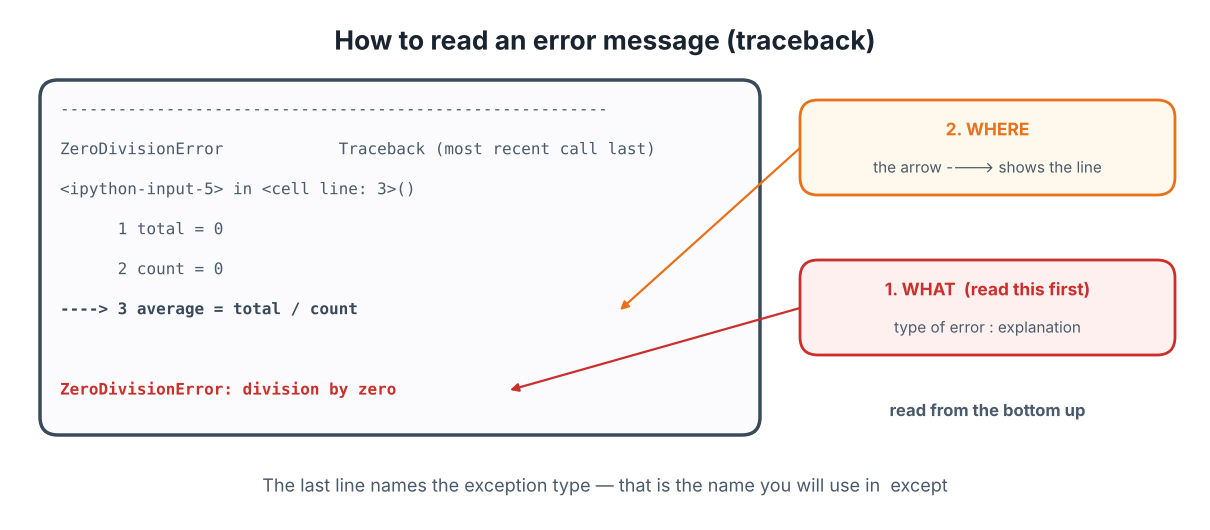

### Exception types: examples [1/3]

The following cells **fail on purpose** - read the last line of every error message. (In Google Colab a failing cell stops *Run all*; run these cells one by one.)

In [ ]:
print "Py"

In [ ]:
x = [0, 1, 2]
x[5]

In [ ]:
country = {'name': 'Latvia', 'capital': 'Riga'}
country['population']

### Exception types: examples [2/3]

In [ ]:
'3' + 4

In [ ]:
int('abc')

In [ ]:
float('3,5')      # decimal comma!

### Exception types: examples [3/3]

In [ ]:
hi

In [ ]:
59 / 0

In [ ]:
open('files/missing.csv')

In [ ]:
import numpy2

### The most common exceptions in data work

| Exception | When it happens | Typical data situation |
|---|---|---|
| `ValueError` | the type is right, the value is wrong | `int("n/a")`, `float("3,5")` |
| `TypeError` | the operation does not fit the type | `"3" + 4`, `None + 1`, `len(5)` |
| `KeyError` | the key is not in the dictionary | a record without `'population'` |
| `IndexError` | the index is outside the list | a line with fewer columns than expected |
| `FileNotFoundError` | the file does not exist (wrong name or folder) | a typo in the path, a file not uploaded to Colab |
| `ZeroDivisionError` | division by zero | the average of an empty group |
| `NameError` | the name is not defined | a typo in a variable name, a cell not run |
| `ModuleNotFoundError` | the library is not installed / wrong name | `import numpy2` |

### YOUR TURN 1: name that error
For every line **predict** the exception type before running it. Then run the lines one by one (each in its own cell or inside a `try`) and check.

1. `numbers = [1, 2, 3]; numbers[3]`
2. `"Riga" * "2"`
3. `int("12.5")`
4. `data = {"LV": 1}; data["EE"]`
5. `len(2026)`
6. `open("files/alise.txt")`

In [ ]:
# 1. IndexError      - index 3 does not exist in a list of 3 elements
# 2. TypeError       - a string can be multiplied by an int, not by a string
# 3. ValueError      - "12.5" is not a valid integer (float("12.5") would work)
# 4. KeyError        - the key "EE" is not in the dictionary
# 5. TypeError       - an int has no length
# 6. FileNotFoundError - wrong name (alise instead of alice) or wrong folder

tests = [lambda: [1, 2, 3][3],
         lambda: "Riga" * "2",
         lambda: int("12.5"),
         lambda: {"LV": 1}["EE"],
         lambda: len(2026),
         lambda: open("files/alise.txt")]

for number, test in enumerate(tests, start=1):
    try:
        test()
    except Exception as e:
        print(number, type(e).__name__, "-", e)

## Handling exceptions

Exceptions are not always a bad thing - you just need to **handle** them. Let us review the syntax:

```
try:
    risky code
except SomeError:
    what to do if it happens
else:
    what to do if it did NOT happen
finally:
    what to do in any case
```

Only the code inside `try` is protected; which `except` branch runs depends on the type of the exception
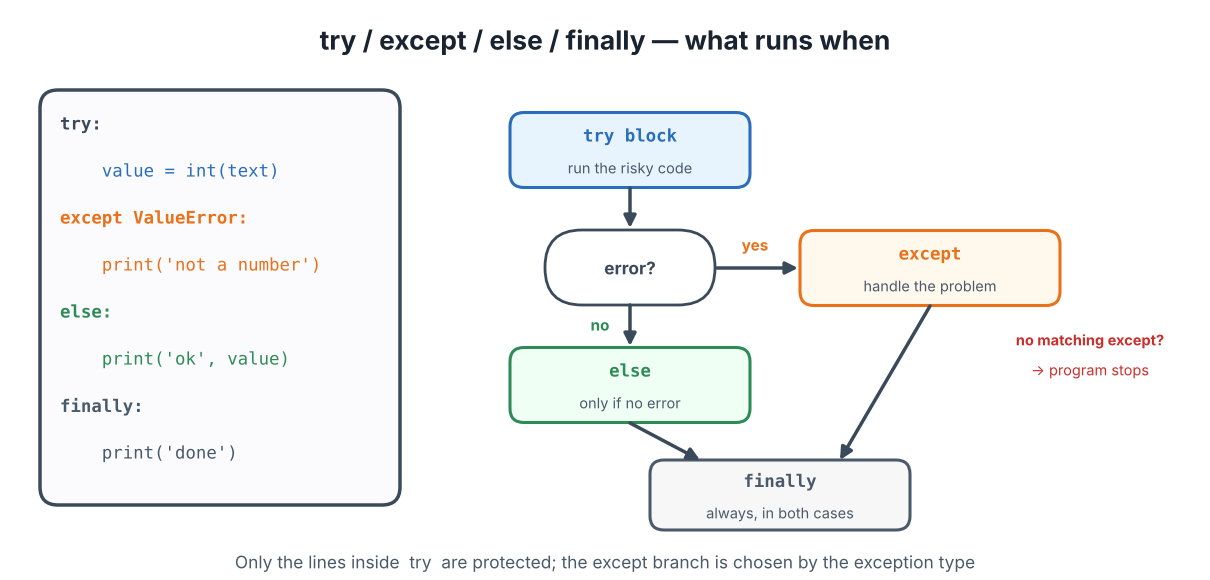

### `try` / `except` / `finally` - nothing goes wrong

`y = 1` - the division works, `except` is skipped, `finally` runs anyway.

In [ ]:
x = 4
y = 1

try:
    print(x / y)
except:
    print("Exception!")
finally:
    print("Executed anyway")

print("Completed!")

### Handling exceptions: ZeroDivisionError

`y = 0` - the division fails, the `except` block runs, `finally` runs, and **the program continues** (compare with the cell `59 / 0` above, which stopped everything).

In [ ]:
x = 4
y = 0

try:
    print(x / y)
except:
    print("Exception!")
finally:
    print("Executed anyway")

print("Completed!")

### Handling exceptions: IndexError - catching a specific type

Several `except` branches: Python takes the **first one that matches** the exception type. A bare `except:` at the end catches everything else.

In [ ]:
x = [1, 2, 3]

try:
    print(x[3])
except IndexError:
    print("No such element - but no matter, let's continue")
except:
    print("Hmmmm... Another exception?")
finally:
    print("Executed anyway")

print("Completed!")

In [ ]:
x = [1, 2, 3]

try:
    print(x[3] + "a")          # x[3] fails first -> IndexError
except IndexError:
    print("No such element")
except TypeError:
    print("Wrong types")

try:
    print(x[2] + "a")          # x[2] is fine, int + str fails -> TypeError
except IndexError:
    print("No such element")
except TypeError:
    print("Wrong types")

### Looking at the exception: `as e`

`except SomeError as e:` stores the exception object in `e`, so we can **print the message** and the type. This is the most useful form: the program continues, but we still know what happened.

In [ ]:
values = ["12", "7", "n/a", "15"]

for value in values:
    try:
        print(int(value) * 2)
    except ValueError as e:
        print("Problem:", e)

In [ ]:
try:
    result = 10 / 0
except Exception as e:                      # Exception = the parent of (almost) all exception types
    print("Type:", type(e).__name__)
    print("Message:", e)

### Why not just `except:` everywhere?

A bare `except:` hides **every** problem - including the ones you want to know about (a typo in a variable name, a wrong key).

* catch the exception type you **expect** (`ValueError`, `FileNotFoundError`, ...)
* catch `Exception as e` only as a last resort - and **print** `e`
* never leave an `except` block empty (`pass`) - the error silently disappears

In [ ]:
prices = [10, 20, 30]

try:
    total = sum(prises)          # a typo: 'prises' instead of 'prices'
except:
    total = 0                    # the typo is hidden - the program runs with a wrong result!

print("Total:", total)

### `else` and `finally`

* `else` runs only if **no** exception happened - keep the "success" code there, outside the protected block
* `finally` runs **always** - used for cleaning up (closing files, connections)

In [ ]:
def parse_number(text):
    try:
        value = float(text)
    except ValueError:
        print(f"'{text}' is not a number")
    else:
        print(f"'{text}' -> {value}")
    finally:
        print("checked:", text)

parse_number("3.5")
parse_number("n/a")

### YOUR TURN 2: safe functions

1. Write a function `safe_divide(a, b)` that returns `a / b`. If `b` is `0`, it prints `Division by zero!` and returns `None`. Test it with `(10, 2)` and `(5, 0)`.
2. Write a function `to_int(text)` that returns `int(text)`, or `None` if the text is not a number (catch `ValueError`). Test it with `"42"`, `"4.2"` and `"abc"`.

In [ ]:
# YOUR CODE HERE:

In [ ]:
# 1.
def safe_divide(a, b):
    try:
        return a / b
    except ZeroDivisionError:
        print("Division by zero!")
        return None

print(safe_divide(10, 2))
print(safe_divide(5, 0))

# 2.
def to_int(text):
    try:
        return int(text)
    except ValueError:
        return None

print(to_int("42"), to_int("4.2"), to_int("abc"))

## Exceptions in data work

Four situations you will meet in every data project:

1. a value that **cannot be converted** to a number
2. a **file** that is not there
3. a **key** that is missing in some records


### 1. Converting messy values

A column from a real file: numbers as strings, decimal commas, `n/a`, empty cells. One helper function with `try` / `except` cleans the whole column.

In [ ]:
def to_number(text):
    "Convert text to float; return None if it is not possible"
    try:
        return float(text.replace(",", "."))      # decimal comma -> decimal point
    except ValueError:
        return None

raw = ["12", "7.5", "n/a", "", "3,5", "15"]
clean = []
for value in raw:
    clean.append(to_number(value))

print(clean)

In [ ]:
numbers = [value for value in clean if value is not None]     # keep only the real numbers
print("Valid values:", len(numbers), "of", len(raw))
print("Average:", sum(numbers) / len(numbers))

### 2. A file that is not there

`FileNotFoundError` is the most common error of Lab 3 - a typo in the name, a file that was not uploaded to Colab, a wrong folder. Handle it with a clear message instead of a traceback.

In [ ]:
filename = 'files/missing.csv'

try:
    with open(filename, 'r', encoding='utf-8') as file:
        text = file.read()
    print("Read", len(text), "symbols")
except FileNotFoundError:
    print(f"File not found: {filename} - check the name and the folder")

### 2. Closing the file - `finally` vs `with`

The classic use of `finally`: a file opened with `open()` must be closed even if an error happens in between. The `with` statement does exactly this for you - that is why we always use `with`.

In [ ]:
f = None

try:
    f = open("demofile.txt", "w")
    f.write(4 / 0)                       # fails before anything is written
except ZeroDivisionError:
    print("Exception is skipped")
finally:
    print("File is closed anyway")
    if f:
        f.close()

In [ ]:
# the same with 'with' - no finally needed, the file is closed automatically
try:
    with open("demofile.txt", "w") as f:
        f.write(4 / 0)
except ZeroDivisionError:
    print("Exception is skipped, the file is already closed:", f.closed)

### 3. A key that is missing

In 3.2 not every country received a `population`. Two equally good ways to deal with it
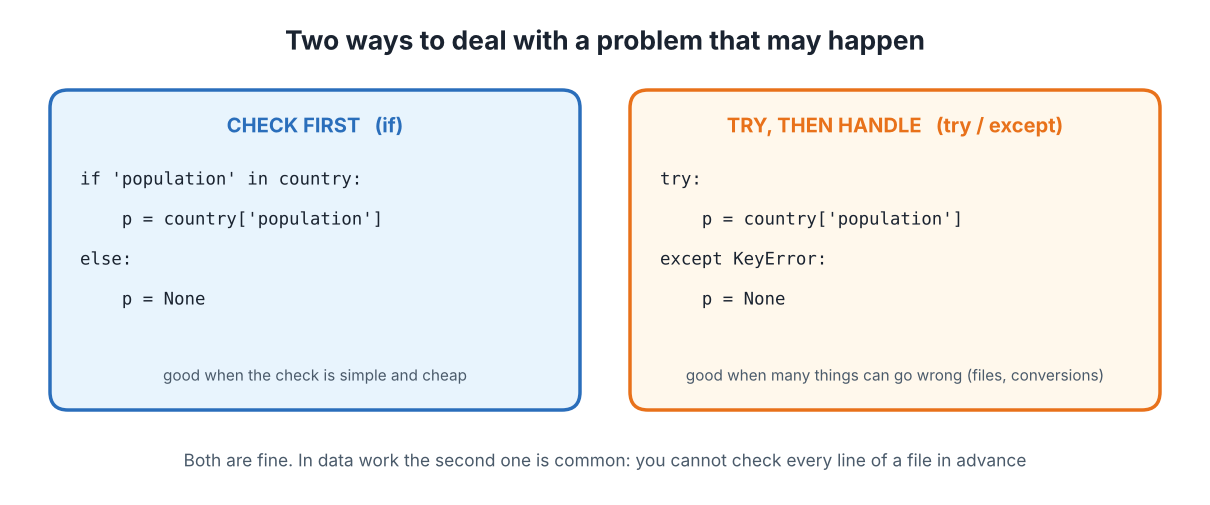

In [ ]:
countries = {
    'LV': {'name': 'Latvia', 'population': 1883162},
    'EE': {'name': 'Estonia', 'population': 1330068},
    'AQ': {'name': 'Antarctica'},                       # no population
}

# check first
for code in countries:
    country = countries[code]
    if 'population' in country:
        print(country['name'], country['population'])
    else:
        print(country['name'], "- no data")

In [ ]:
# try, then handle
for code in countries:
    country = countries[code]
    try:
        print(country['name'], country['population'])
    except KeyError as e:
        print(country['name'], "- missing key:", e)

In [ ]:
# the third way for dictionaries: .get() returns a default instead of an error
for code in countries:
    country = countries[code]
    print(country['name'], country.get('population', "no data"))

## Raising your own exceptions

Sometimes **your** function receives data it cannot work with. Instead of returning a wrong result, it should **raise** an exception with a clear message:

```
raise ValueError("explanation for the caller")
```

* `assert` (3.1) is for **testing** your own code
* `raise` is for **protecting** the user of your function from wrong input

In [ ]:
def average(values):
    "Return the average of a non-empty list of numbers"
    if len(values) == 0:
        raise ValueError("average of an empty list is not defined")
    return sum(values) / len(values)

print(average([2, 4, 6]))

In [ ]:
average([])

The caller of the function decides what to do with it - exactly as with the built-in exceptions:

In [ ]:
groups = {"A": [3, 4, 5], "B": [], "C": [10]}

for name in groups:
    try:
        print(name, average(groups[name]))
    except ValueError as e:
        print(name, "-", e)

## Summary

* three kinds of problems: **syntax error** (fix the typo), **exception** (handle it), **logic error** (test with `assert`)
* read a traceback **from the bottom**: the last line = exception type + message, the arrow = the line
* `try` / `except SomeError as e` / `else` / `finally` - only the code inside `try` is protected; `e` holds the message
* catch the **specific** type you expect; `except Exception as e` only as a last resort, never an empty `except:`
* data work: convert with a helper function (`ValueError`), check files (`FileNotFoundError`), missing keys (`in`, `.get()`, `KeyError`), handle errors **inside the loop** and count them
* `raise ValueError("message")` protects the user of your function from wrong input

# Thank you